In [2]:
import numpy as np
import pandas as pd
import plotly.express as px
import streamlit as st

In [3]:
df= pd.read_csv(r'C:\Users\Maison\Downloads\Sales_transactions_2022_2025\Sales_transactions_2022_2025.csv')
df

,Transaction_ID,Order_ID,Customer_ID,Customer_Name,Customer_Age,Customer_Gender,Customer_Segment,Order_Date,Order_Time,Sales_Channel,...,Order_Status,Shipping_Method,Delivery_Days,Return_Flag,Return_Reason,Sales_Representative,Promotion_Code,Customer_Rating,Inventory_Level,Order_Year
0,T02016694,O0116694,C01482,Sophia Smith,28.0,Male,Consumer,2022-10-06,11:30:55,Online,...,Completed,Standard,4.0,No,NaN,James Anderson,SAVE10,4.0,81.0,2022
1,T02016374,O0108187,C01591,Hannah King,46.0,Female,Consumer,2024-06-03,17:06:29,Online,...,Completed,Standard,6.0,No,NaN,Ella Lewis,NaN,5.0,123.0,2024
2,T02004099,O0104099,C04140,Emma Wilson,42.0,Male,Consumer,2024-12-19,08:22:11,Online,...,Shipped,Standard,4.0,No,NaN,Liam Davis,NaN,4.0,93.0,2024
3,T02010280,O0110280,C03663,Daniel Clark,18.0,Male,Corporate,2025-10-05,14:32:43,B2B Portal,...,Completed,Next Day,2.0,No,NaN,Grace Harris,HOLIDAY20,NaN,59.0,2025
4,T02012685,O0112685,C02749,Sophia Smith,37.0,Male,Returning Customer,2022-09-13,14:55:16,B2B Portal,...,Completed,Express,2.0,No,NaN,Sophia Brown,NaN,2.0,56.0,2022
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18040,T02006253,O0106253,C03487,Ella Adams,32.0,Male,New Customer,2022-01-11,10:44:18,Online,...,Completed,Express,2.0,No,NaN,Emma Carter,MOM15,5.0,52.0,2022
18041,T02005688,O0102844,C00418,Jack Jones,32.0,Male,Returning Customer,2023-10-09,08:26:43,Retail Store,...,Processing,Standard,3.0,No,NaN,Emma Carter,SAVE10,4.0,107.0,2023
18042,T02011672,O0111672,C03311,Oscar Williams,37.0,Male,Corporate,2025-04-02,17:45:09,Online,...,Completed,Standard,6.0,No,NaN,Sophia Brown,SAVE10,2.0,58.0,2025
18043,T02013094,O0113094,C01590,Benjamin Moore,21.0,Female,New Customer,2022-06-08,15:03:38,Online,...,Completed,Standard,7.0,No,NaN,Noah Wilson,BLACKFRIDAY25,3.0,32.0,2022


In [5]:
df.duplicated().sum()

np.int64(45)

In [6]:
df.drop_duplicates(inplace=True)

In [7]:
df.isna().sum()

Transaction_ID              0
Order_ID                    0
Customer_ID                 0
Customer_Name             108
Customer_Age              216
Customer_Gender           162
Customer_Segment            0
Order_Date                  0
Order_Time                  0
Sales_Channel               0
Store_ID                    0
Store_Name                  0
Country                     0
Region                      0
City                        0
Product_ID                  0
Product_Name              144
Product_Category            0
Product_Subcategory         0
Quantity                    0
Unit_Price                  0
Discount_Percentage         0
Sales_Amount                0
Cost_Amount                 0
Profit                      0
Payment_Method            144
Order_Status                0
Shipping_Method             0
Delivery_Days             162
Return_Flag                 0
Return_Reason           16127
Sales_Representative        0
Promotion_Code           9712
Customer_R

In [8]:
round(df.isna().mean()*100,2)

Transaction_ID           0.00
Order_ID                 0.00
Customer_ID              0.00
Customer_Name            0.60
Customer_Age             1.20
Customer_Gender          0.90
Customer_Segment         0.00
Order_Date               0.00
Order_Time               0.00
Sales_Channel            0.00
Store_ID                 0.00
Store_Name               0.00
Country                  0.00
Region                   0.00
City                     0.00
Product_ID               0.00
Product_Name             0.80
Product_Category         0.00
Product_Subcategory      0.00
Quantity                 0.00
Unit_Price               0.00
Discount_Percentage      0.00
Sales_Amount             0.00
Cost_Amount              0.00
Profit                   0.00
Payment_Method           0.80
Order_Status             0.00
Shipping_Method          0.00
Delivery_Days            0.90
Return_Flag              0.00
Return_Reason           89.59
Sales_Representative     0.00
Promotion_Code          53.96
Customer_R

In [9]:
pd.crosstab(df['Return_Flag'], df['Return_Reason'], dropna=False)

Return_Reason,Changed Mind,Damaged,Defective,Late Delivery,Other,Wrong Item,NaN
Return_Flag,,,,,,,
No,0,0,0,0,0,0,16127
Yes,300,312,302,331,311,317,0


In [10]:
df['Return_Reason'] = df['Return_Reason'].fillna('Not Returned')

In [11]:
df['Return_Reason'].isnull().sum()

np.int64(0)

In [12]:
df['Promotion_Code'] = df['Promotion_Code'].fillna('No Promotion')

In [14]:
categorical_cols = [
    'Customer_Name',
    'Customer_Gender',
    'Product_Name',
    'Payment_Method'
]

df[categorical_cols] = df[categorical_cols].fillna('Unknown')

In [15]:
df[['Customer_Age', 'Quantity', 'Unit_Price', 'Discount_Percentage',
    'Sales_Amount', 'Cost_Amount', 'Profit', 'Delivery_Days']].describe().T

,count,mean,std,min,25%,50%,75%,max
Customer_Age,17784.0,38.916948,10.723353,4.00,32.0000,39.000,46.0000,112.00
Quantity,18000.0,2.126500,1.784690,-3.00,1.0000,2.000,3.0000,11.00
Unit_Price,18000.0,232.775236,294.249699,21.39,52.9575,99.845,285.7825,1425.09
Discount_Percentage,18000.0,6.254722,6.879860,0.00,0.0000,5.000,10.0000,110.00
Sales_Amount,18000.0,457.449478,857.097154,16.68,78.5250,168.845,472.7425,14303.07
Cost_Amount,18000.0,366.132677,706.335962,12.17,56.1050,122.315,376.1450,10791.00
Profit,18000.0,91.413300,167.856392,-299.31,19.4900,40.190,93.3000,3512.08
Delivery_Days,17838.0,2.262361,2.321260,0.00,0.0000,1.000,4.0000,10.00


In [16]:
df = df.loc[~df['Customer_Age'].isin([4, 112])].reset_index(drop=True)

In [17]:
df = df.loc[df['Quantity'] > 0].reset_index(drop=True)

In [18]:
df['Customer_Age'].median()

np.float64(39.0)

In [19]:
df['Customer_Age'] = df['Customer_Age'].fillna(
    df['Customer_Age'].median()
)

In [23]:
df['Customer_Age'].isna().sum()

np.int64(0)

In [24]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17990 entries, 0 to 17989
Data columns (total 36 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Transaction_ID        17990 non-null  str    
 1   Order_ID              17990 non-null  str    
 2   Customer_ID           17990 non-null  str    
 3   Customer_Name         17990 non-null  str    
 4   Customer_Age          17990 non-null  float64
 5   Customer_Gender       17990 non-null  str    
 6   Customer_Segment      17990 non-null  str    
 7   Order_Date            17990 non-null  str    
 8   Order_Time            17990 non-null  str    
 9   Sales_Channel         17990 non-null  str    
 10  Store_ID              17990 non-null  str    
 11  Store_Name            17990 non-null  str    
 12  Country               17990 non-null  str    
 13  Region                17990 non-null  str    
 14  City                  17990 non-null  str    
 15  Product_ID            17990 no

In [25]:
df['Customer_Age'] = df['Customer_Age'].astype('Int64')

In [26]:
df['Inventory_Level'] = df['Inventory_Level'].fillna(
    df['Inventory_Level'].median()
)

In [28]:
df['Order_Date'] = pd.to_datetime(
    df['Order_Date'], errors='coerce'
)

df['Order_Time'] = pd.to_datetime(
    df['Order_Time'], format='%H:%M:%S', errors='coerce'
).dt.time

In [29]:
print(df[['Order_Date', 'Order_Time']].dtypes)

df[['Order_Date', 'Order_Time']].head()

Order_Date    datetime64[us]
Order_Time            object
dtype: object


,Order_Date,Order_Time
0,2022-10-06,11:30:55
1,2024-06-03,17:06:29
2,2024-12-19,08:22:11
3,2025-10-05,14:32:43
4,2022-09-13,14:55:16


In [30]:
df.loc[df['Delivery_Days'].isna(), 'Order_Status'].value_counts()

Order_Status
Completed     106
Shipped        18
Returned       17
Processing     14
Cancelled       6
completed       1
Name: count, dtype: int64

In [31]:
df['Order_Status'] = df['Order_Status'].str.strip().str.title()

In [32]:
pd.crosstab(
    [df['Order_Status'], df['Shipping_Method']],
    df['Delivery_Days'].isna(),
    dropna=False
)

Delivery_Days                 False  True 
Order_Status Shipping_Method              
Cancelled    Express            110      0
             Next Day            50      0
             Pickup             339      3
             Standard           387      3
Completed    Express           1523      8
             Next Day           602      7
             Pickup            4415     44
             Standard          4883     48
Processing   Express            192      1
             Next Day            60      1
             Pickup             550      4
             Standard           603      8
Returned     Express            206      3
             Next Day            90      0
             Pickup             587      5
             Standard           697      9
Shipped      Express            331      1
             Next Day           139      0
             Pickup             980     11
             Standard          1084      6

In [36]:
df['Shipping_Method'] = df['Shipping_Method'].str.strip().str.title()

In [37]:
df.groupby('Shipping_Method')['Delivery_Days'].median()

Shipping_Method
Express     1.0
Next Day    1.0
Pickup      0.0
Standard    5.0
Name: Delivery_Days, dtype: float64

In [38]:
df.groupby ('Shipping_Method')['Delivery_Days'].transform(lambda x : x.fillna (x.median()))

0        4.0
1        6.0
2        4.0
3        2.0
4        2.0
        ... 
17985    2.0
17986    3.0
17987    6.0
17988    7.0
17989    0.0
Name: Delivery_Days, Length: 17990, dtype: float64

In [39]:
round(df.isna().mean()*100,2)

Transaction_ID           0.00
Order_ID                 0.00
Customer_ID              0.00
Customer_Name            0.00
Customer_Age             0.00
Customer_Gender          0.00
Customer_Segment         0.00
Order_Date               0.00
Order_Time               0.00
Sales_Channel            0.00
Store_ID                 0.00
Store_Name               0.00
Country                  0.00
Region                   0.00
City                     0.00
Product_ID               0.00
Product_Name             0.00
Product_Category         0.00
Product_Subcategory      0.00
Quantity                 0.00
Unit_Price               0.00
Discount_Percentage      0.00
Sales_Amount             0.00
Cost_Amount              0.00
Profit                   0.00
Payment_Method           0.00
Order_Status             0.00
Shipping_Method          0.00
Delivery_Days            0.90
Return_Flag              0.00
Return_Reason            0.00
Sales_Representative     0.00
Promotion_Code           0.00
Customer_R

In [41]:
median= {'Pickup': 0, 'Next Day': 1, 'Express': 1, 'Standard': 5}
df['Delivery_Days'] = df['Delivery_Days'].fillna(df['Shipping_Method'].map(median))
print(df['Delivery_Days'].isna().sum())

0


In [43]:
df = df.loc[
    df['Discount_Percentage'].between(0, 100)
].reset_index(drop=True)

In [44]:
cat_cols = df.select_dtypes(include=['str', 'object']).columns

In [45]:
cat_cols

Index(['Transaction_ID', 'Order_ID', 'Customer_ID', 'Customer_Name',
       'Customer_Gender', 'Customer_Segment', 'Order_Time', 'Sales_Channel',
       'Store_ID', 'Store_Name', 'Country', 'Region', 'City', 'Product_ID',
       'Product_Name', 'Product_Category', 'Product_Subcategory',
       'Payment_Method', 'Order_Status', 'Shipping_Method', 'Return_Flag',
       'Return_Reason', 'Sales_Representative', 'Promotion_Code'],
      dtype='str')

In [46]:
for col in cat_cols :
    print(col)
    print(df[col].nunique())
    print(df[col].unique())
    print('-'*50)

Transaction_ID
17989
<ArrowStringArray>
['T02016694', 'T02016374', 'T02004099', 'T02010280', 'T02012685', 'T02003704',
 'T02016542', 'T02013460', 'T02001029', 'T02001635',
 ...
 'T02005105', 'T02004187', 'T02007434', 'T02015694', 'T02014571', 'T02006253',
 'T02005688', 'T02011672', 'T02013094', 'T02011617']
Length: 17989, dtype: str
--------------------------------------------------
Order_ID
14533
<ArrowStringArray>
['O0116694', 'O0108187', 'O0104099', 'O0110280', 'O0112685', 'O0101852',
 'O0116542', 'O0113460', 'O0101029', 'O0101635',
 ...
 'O0105985', 'O0105105', 'O0104187', 'O0107434', 'O0107847', 'O0114571',
 'O0106253', 'O0111672', 'O0113094', 'O0111617']
Length: 14533, dtype: str
--------------------------------------------------
Customer_ID
4882
<ArrowStringArray>
['C01482', 'C01591', 'C04140', 'C03663', 'C02749', 'C00959', 'C02232',
 'C00719', 'C01511', 'C04415',
 ...
 'C04458', 'C00754', 'C00210', 'C01919', 'C00366', 'C05043', 'C03194',
 'C00443', 'C01531', 'C03311']
Length: 4

In [47]:
df['Region'] = df['Region'].str.strip().replace({
    'British columbia': 'British Columbia',
    'NRW': 'North Rhine-Westphalia',
    'North East': 'Northeast'
})

In [48]:
df['City'] = df['City'].str.strip().str.title()

In [49]:
df['Product_Category'] = (
    df['Product_Category'].str.strip().str.title()
)

In [50]:
for col in ['Region', 'City', 'Product_Category']:
    print(col)
    print(df[col].unique())
    print('-' * 40)

Region
<ArrowStringArray>
[                  'West',        'New South Wales',          'Île-de-France',
              'Northeast',                'Midwest',                'Ontario',
       'British Columbia',                  'South',                'England',
 'North Rhine-Westphalia',                'Bavaria']
Length: 11, dtype: str
----------------------------------------
City
<ArrowStringArray>
['Los Angeles',      'Sydney',       'Paris',    'New York',     'Chicago',
     'Toronto',   'Vancouver',      'Austin',      'London',     'Cologne',
  'Manchester',      'Munich']
Length: 12, dtype: str
----------------------------------------
Product_Category
<ArrowStringArray>
['Electronics', 'Office Supplies', 'Furniture', 'Appliances']
Length: 4, dtype: str
----------------------------------------


In [51]:
df['Customer_Gender'] = (
    df['Customer_Gender'].str.strip().str.title()
)

In [58]:
df['Customer_Gender'] = (
    df['Customer_Gender']
    .str.strip()
    .replace({
        'male': 'Male',
        'FEMALE': 'Female',
        'Non-binary': 'Non-Binary '
    })
)

In [59]:
df['Payment_Method'] = (
    df['Payment_Method']
    .str.strip()
    .replace({
        'credit card': 'Credit Card',
        'DebitCard': 'Debit Card',
        'paypal': 'PayPal',
        'Bank transfer': 'Bank Transfer'
    })
)

In [60]:
for col in ['Customer_Gender', 'Sales_Channel',
            'Order_Status', 'Payment_Method']:
    print(f'\n{col}:')
    print(df[col].value_counts(dropna=False))


Customer_Gender:
Customer_Gender
Female         8789
Male           8489
Non-Binary      541
Unknown         162
Non-Binary        8
Name: count, dtype: int64

Sales_Channel:
Sales_Channel
Online          8190
Retail Store    6219
B2B Portal      2123
Phone Order     1457
Name: count, dtype: int64

Order_Status:
Order_Status
Completed     11530
Shipped        2552
Returned       1596
Processing     1419
Cancelled       892
Name: count, dtype: int64

Payment_Method:
Payment_Method
Credit Card      6800
Debit Card       3948
PayPal           2816
Bank Transfer    2156
Apple Pay        1087
Cash             1038
Unknown           144
Name: count, dtype: int64


In [61]:
df.loc[df['Customer_Gender'].str.contains('binary', case=False, na=False), 'Customer_Gender'] = 'Non-Binary'

In [62]:
print(df['Customer_Gender'].value_counts())

Customer_Gender
Female        8789
Male          8489
Non-Binary     549
Unknown        162
Name: count, dtype: int64


In [63]:
df['Calculated_Profit'] = (
    df['Sales_Amount'] - df['Cost_Amount']
)

df['Profit_Mismatch'] = ~np.isclose(
    df['Profit'],
    df['Calculated_Profit'],
    atol=0.01
)

print("Profit mismatches:", df['Profit_Mismatch'].sum())

Profit mismatches: 110


In [64]:
df.loc[
    df['Profit_Mismatch'],
    ['Transaction_ID', 'Sales_Amount', 'Cost_Amount',
     'Profit', 'Calculated_Profit']
].head(10)

,Transaction_ID,Sales_Amount,Cost_Amount,Profit,Calculated_Profit
274,T02011502,234.83,213.11,92.44,21.72
442,T02012573,114.16,78.59,28.66,35.57
802,T02002177,223.92,193.15,69.78,30.77
817,T02013340,1289.96,1107.31,222.30,182.65
962,T02009106,135.72,84.99,124.85,50.73
1134,T02009758,42.28,29.37,12.08,12.91
1264,T02005711,546.27,436.33,126.43,109.94
1552,T02007133,181.06,148.44,121.77,32.62
1664,T02002984,680.61,502.21,174.64,178.40
1855,T02000839,225.45,188.78,296.92,36.67


In [65]:
print(df['Profit_Mismatch'].sum())

110


In [66]:
errors_110 = df.loc[df['Profit_Mismatch']].copy()
errors_110.to_csv('profit_errors_110_rows.csv', index=False)
print(len(errors_110)) 

110


In [67]:
import os
print(os.getcwd())                              
print(os.path.exists('profit_errors_110_rows.csv'))

C:\Users\Maison
True


In [68]:
incorrect = df['Profit_Mismatch']

df.loc[incorrect, 'Sales_Amount'] = (
    df['Quantity'] * df['Unit_Price'] * (1 - df['Discount_Percentage'] / 100)
).round(2)

df.loc[incorrect, 'Profit'] = (df['Sales_Amount'] - df['Cost_Amount']).round(2)

In [69]:
df['Calculated_Profit'] = (df['Sales_Amount'] - df['Cost_Amount']).round(2)
df['Profit_Mismatch'] = (df['Profit'] - df['Calculated_Profit']).abs() > 0.02
print("Wrong Rows:", df['Profit_Mismatch'].sum())

Wrong Rows: 0


In [70]:
df.columns.tolist()

['Transaction_ID',
 'Order_ID',
 'Customer_ID',
 'Customer_Name',
 'Customer_Age',
 'Customer_Gender',
 'Customer_Segment',
 'Order_Date',
 'Order_Time',
 'Sales_Channel',
 'Store_ID',
 'Store_Name',
 'Country',
 'Region',
 'City',
 'Product_ID',
 'Product_Name',
 'Product_Category',
 'Product_Subcategory',
 'Quantity',
 'Unit_Price',
 'Discount_Percentage',
 'Sales_Amount',
 'Cost_Amount',
 'Profit',
 'Payment_Method',
 'Order_Status',
 'Shipping_Method',
 'Delivery_Days',
 'Return_Flag',
 'Return_Reason',
 'Sales_Representative',
 'Promotion_Code',
 'Customer_Rating',
 'Inventory_Level',
 'Order_Year',
 'Calculated_Profit',
 'Profit_Mismatch']

In [71]:
df['Profit'] = df['Calculated_Profit']

print((df['Profit'] != df['Calculated_Profit']).sum())

0


In [72]:
df.drop(columns=['Calculated_Profit', 'Profit_Mismatch', 'Profit_Difference'],
        inplace=True, errors='ignore')

print(df.columns.tolist())

['Transaction_ID', 'Order_ID', 'Customer_ID', 'Customer_Name', 'Customer_Age', 'Customer_Gender', 'Customer_Segment', 'Order_Date', 'Order_Time', 'Sales_Channel', 'Store_ID', 'Store_Name', 'Country', 'Region', 'City', 'Product_ID', 'Product_Name', 'Product_Category', 'Product_Subcategory', 'Quantity', 'Unit_Price', 'Discount_Percentage', 'Sales_Amount', 'Cost_Amount', 'Profit', 'Payment_Method', 'Order_Status', 'Shipping_Method', 'Delivery_Days', 'Return_Flag', 'Return_Reason', 'Sales_Representative', 'Promotion_Code', 'Customer_Rating', 'Inventory_Level', 'Order_Year']


In [93]:
df.to_csv('cleaned_retail_dataset.csv', index=False)

In [94]:
import os

print(os.getcwd())

C:\Users\Maison


In [95]:
import os
os.getcwd()

'C:\\Users\\Maison'

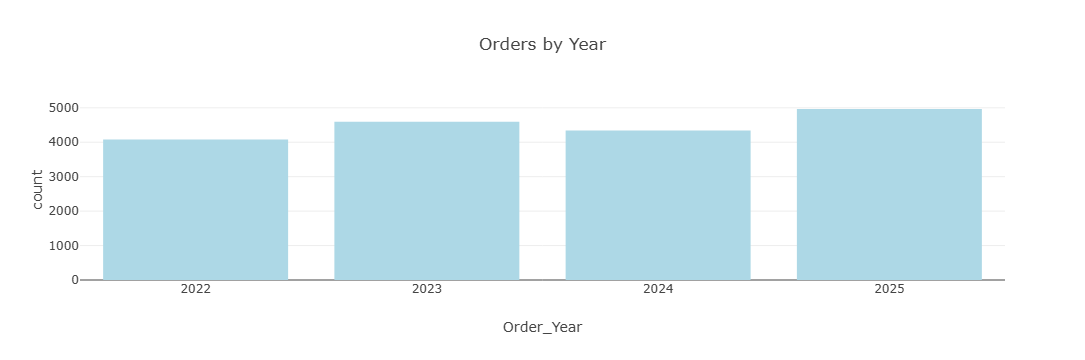

In [73]:
px.bar(df['Order_Year'].value_counts().reset_index(),x='Order_Year',y='count',title='Orders by Year',color_discrete_sequence=['lightblue']).update_xaxes(dtick=1,tickmode='linear').show()

In [74]:
monthly_sales = (
    df.groupby(df['Order_Date'].dt.to_period('M'))['Sales_Amount']
    .sum()
    .reset_index()
)

monthly_sales['Order_Date'] = monthly_sales['Order_Date'].dt.to_timestamp()

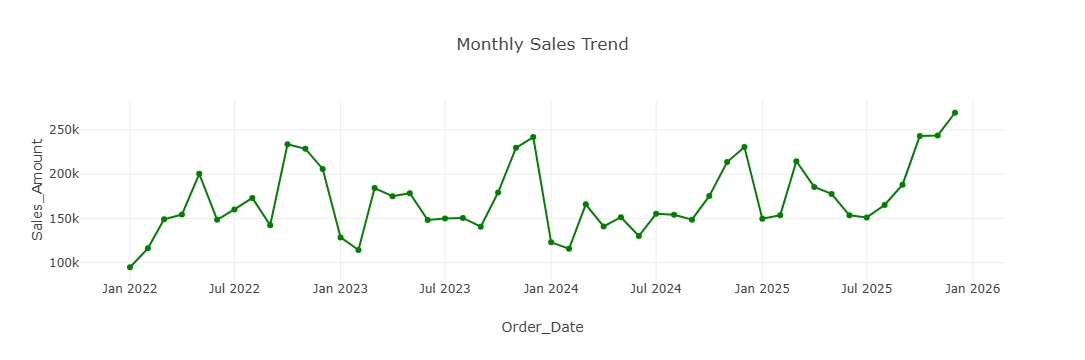

In [75]:
px.line(
    monthly_sales,
    x='Order_Date',
    y='Sales_Amount',
    title='Monthly Sales Trend',
    markers=True).update_traces(line_color='green').show()

In [76]:
df['Order_Date'].max()

Timestamp('2025-12-31 00:00:00')

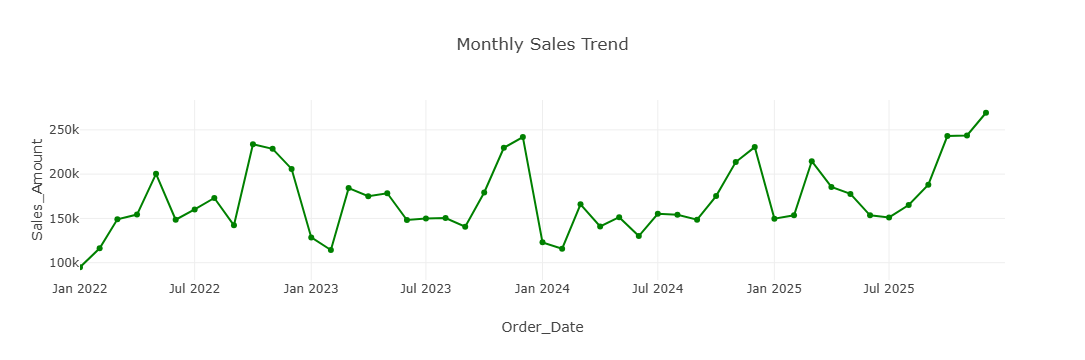

In [77]:
px.line(
    monthly_sales,
    x='Order_Date',
    y='Sales_Amount',
    title='Monthly Sales Trend',
    markers=True
).update_traces(
    line_color='green'
).update_xaxes(
    range=['2022-01-01', '2025-12-31']
).show()

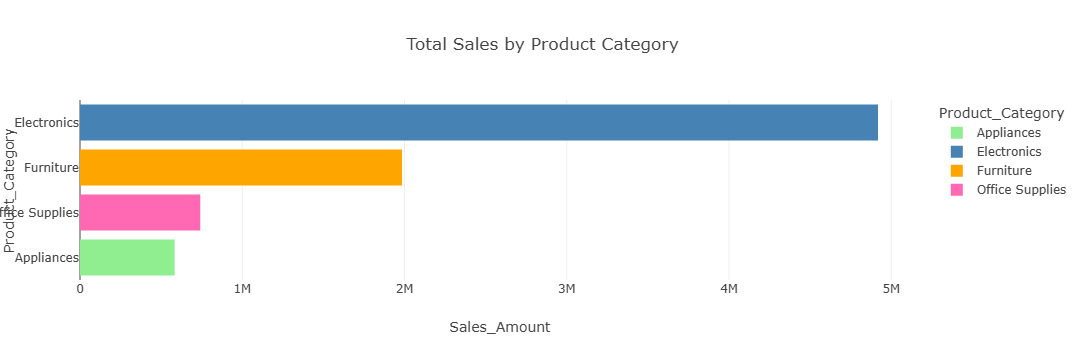

In [78]:
custome_colors = {
    'Appliances': '#90EE90',
    'Electronics': '#4682B4',
    'Furniture': '#FFA500',
    'Office Supplies': '#FF69B4'
}

px.bar(
    df.groupby('Product_Category', as_index=False)['Sales_Amount'].sum(),
    x='Sales_Amount',
    y='Product_Category',
    orientation='h',
    title='Total Sales by Product Category',
    color='Product_Category',
    color_discrete_map=custome_colors
).update_layout(
    yaxis={'categoryorder': 'total ascending'}
).show()

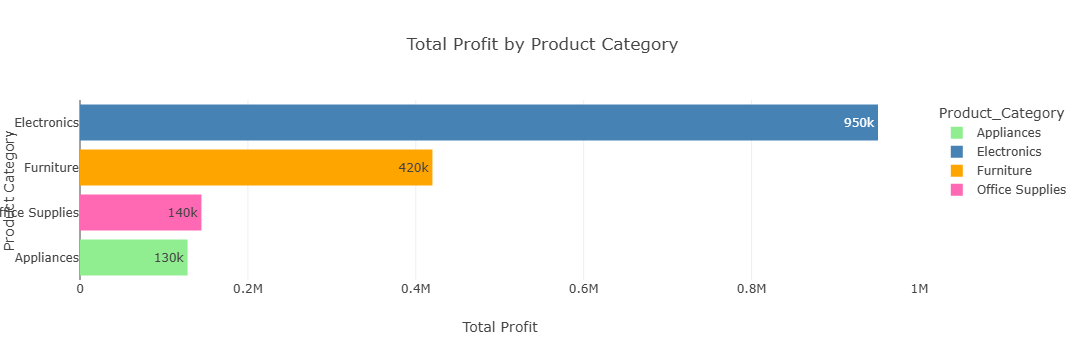

In [79]:
px.bar(
    df.groupby('Product_Category', as_index=False)['Profit'].sum(),
    x='Profit',
    y='Product_Category',
    orientation='h',
    title='Total Profit by Product Category',
    color='Product_Category',
    color_discrete_map=custome_colors,
    text_auto='.2s'
).update_layout(
    yaxis={'categoryorder': 'total ascending'},
    xaxis_title='Total Profit',
    yaxis_title='Product Category'
).show()

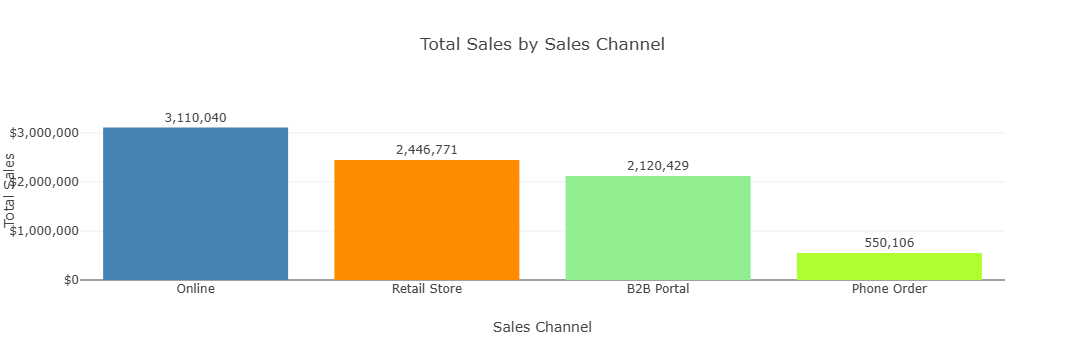

In [80]:
sales_channel = (
    df.groupby('Sales_Channel', as_index=False)['Sales_Amount']
    .sum()
    .sort_values('Sales_Amount', ascending=False)
)

channel_colors = {
    'Online': '#4682B4',
    'B2B Portal': '#90EE90',
    'Phone Order': '#adff2f',
    'Retail Store': '#ff8c00'
}

px.bar(
    sales_channel,
    x='Sales_Channel',
    y='Sales_Amount',
    title='Total Sales by Sales Channel',
    color='Sales_Channel',
    color_discrete_map=channel_colors,
    text=sales_channel['Sales_Amount'].map(lambda x: f'{x:,.0f}')
).update_layout(
    xaxis_title='Sales Channel',
    yaxis_title='Total Sales',
    yaxis_tickprefix='$',
    yaxis_tickformat=',.0f',
    showlegend=False,
    xaxis={'categoryorder': 'total descending'}
).update_traces(
    textposition='outside'
).show()

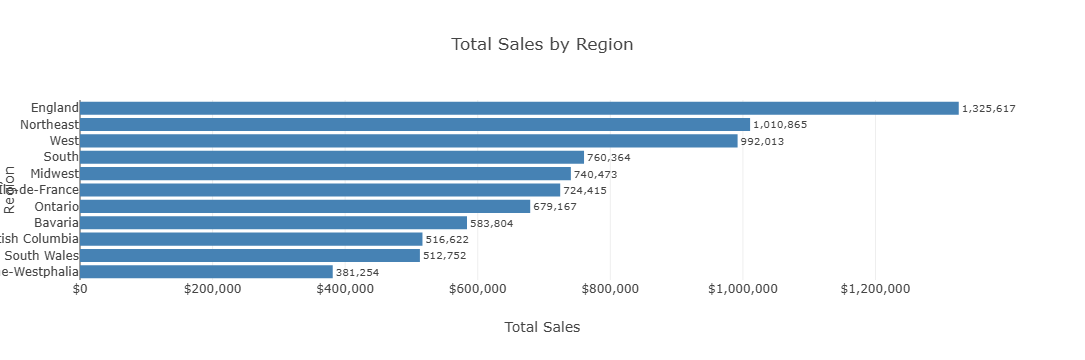

In [81]:
sales_region = (
    df.groupby('Region', as_index=False)['Sales_Amount']
    .sum()
    .sort_values('Sales_Amount', ascending=True)
)

px.bar(
    sales_region,
    x='Sales_Amount',
    y='Region',
    orientation='h',
    title='Total Sales by Region',
     color_discrete_sequence=['#4682B4'],
    text=sales_region['Sales_Amount'].map(lambda x: f'{x:,.0f}')
).update_layout(
    xaxis_title='Total Sales',
    yaxis_title='Region',
    xaxis_tickprefix='$',
    xaxis_tickformat=',.0f',
    showlegend=False
).update_traces(
    textposition='outside',
    cliponaxis=False
).show()

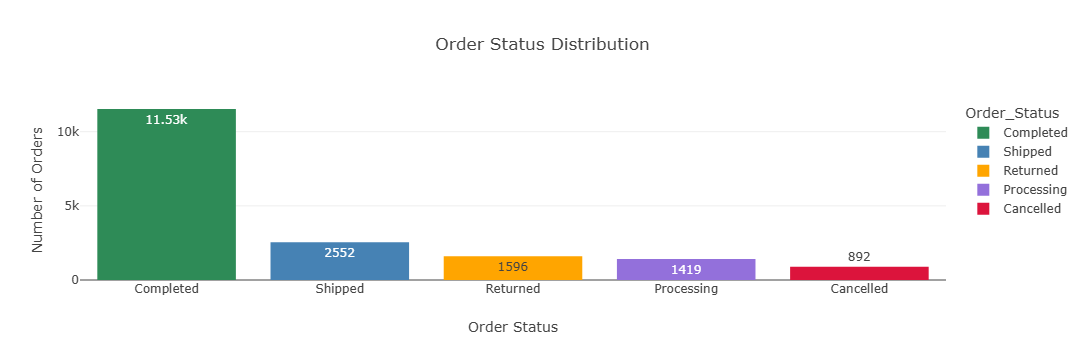

In [82]:
status_colors = {
    'Completed': '#2E8B57',
    'Shipped': '#4682B4',
    'Returned': '#FFA500',
    'Processing': '#9370DB',
    'Cancelled': '#DC143C'
}

px.bar(
    df['Order_Status'].value_counts().reset_index(),
    x='Order_Status',
    y='count',
    title='Order Status Distribution',
    color='Order_Status',
    color_discrete_map=status_colors,
    text_auto=True
).update_layout(
    xaxis_title='Order Status',
    yaxis_title='Number of Orders'
).show()

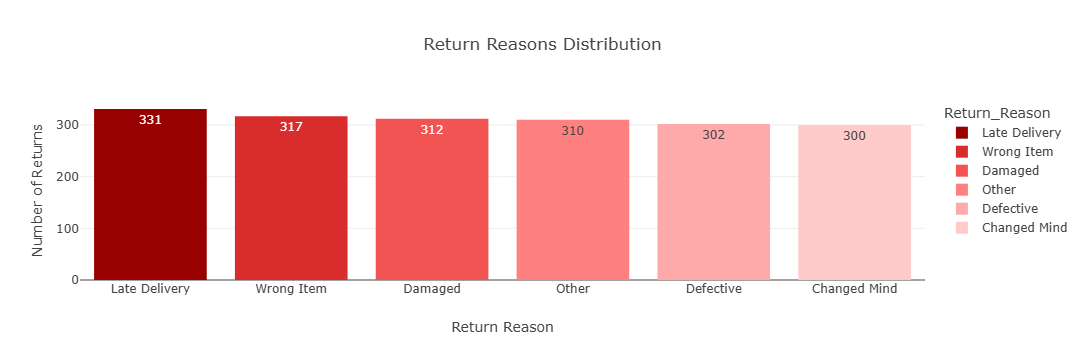

In [83]:
return_colors = {
    'Late Delivery': '#990000', 
    'Wrong Item': '#D92D2D', 
    'Damaged': '#F25353', 
    'Other': '#FF8080', 
    'Defective': '#FFAAAA', 
    'Changed Mind': '#FFCACA' 
}

px.bar(
    df[df['Return_Flag'] == 'Yes']['Return_Reason']
    .value_counts()
    .reindex([
        'Late Delivery',
        'Wrong Item',
        'Damaged',
        'Other',
        'Defective',
        'Changed Mind'
    ], fill_value=0)
    .rename_axis('Return_Reason')
    .reset_index(name='count'),
    x='Return_Reason',
    y='count',
    title='Return Reasons Distribution',
    color='Return_Reason',
    color_discrete_map=return_colors,
    text_auto=True
).update_layout(
    xaxis_title='Return Reason',
    yaxis_title='Number of Returns'
).show()

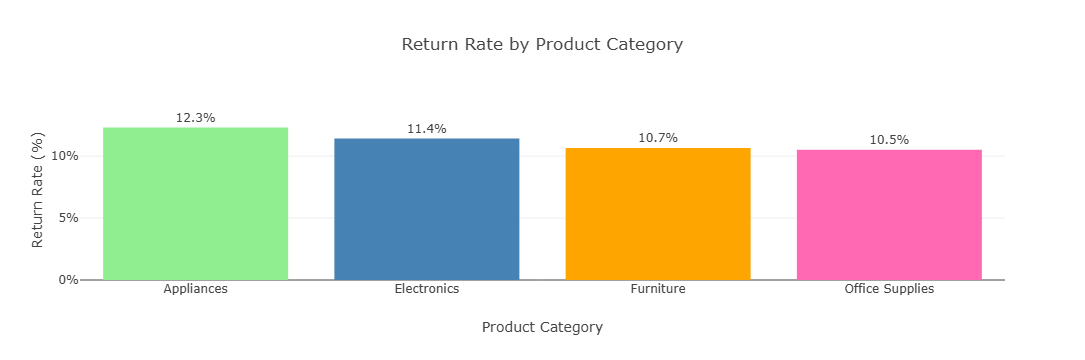

In [88]:
return_rate = (
    df.groupby('Product_Category')
    .agg(
        Total_Orders=('Order_ID', 'nunique'),
        Returned_Orders=('Return_Flag', lambda x: (x == 'Yes').sum())
    )
    .reset_index()
)

return_rate['Return_Rate'] = (
    return_rate['Returned_Orders'] / return_rate['Total_Orders'] * 100
)
return_rate = return_rate.sort_values('Return_Rate', ascending=False)

return_colors = {
    'Appliances': '#90EE90',
    'Electronics': '#4682B4',
    'Furniture': '#FFA500',
    'Office Supplies': '#FF69B4'
}

px.bar(
    return_rate,
    x='Product_Category',
    y='Return_Rate',
    title='Return Rate by Product Category',
    color='Product_Category',
    color_discrete_map=return_colors,
    text=return_rate['Return_Rate'].map(lambda x: f'{x:.1f}%')
).update_layout(
    xaxis_title='Product Category',
    yaxis_title='Return Rate (%)',
    yaxis_ticksuffix='%',
    showlegend=False
).update_traces(
    textposition='outside'
).show()

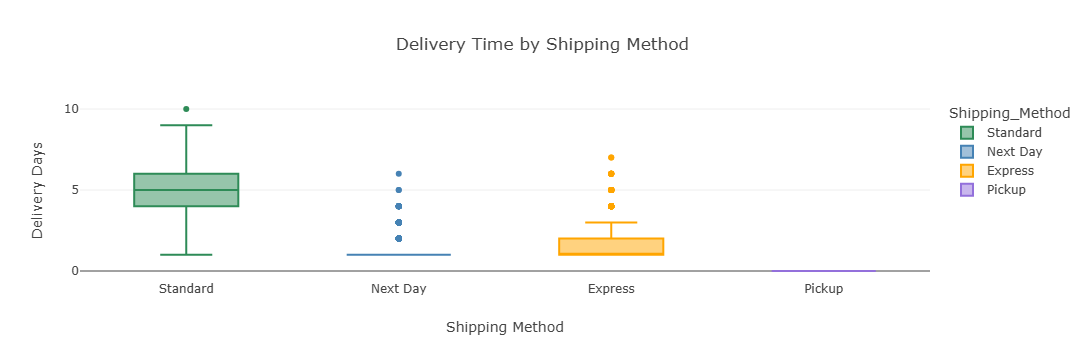

In [89]:
shipping_colors = {
    'Standard': '#2E8B57',
    'Next Day': '#4682B4',
    'Express': '#FFA500',
    'Pickup': '#9370DB'
}

px.box(
    df.dropna(subset=['Delivery_Days']),
    x='Shipping_Method',
    y='Delivery_Days',
    color='Shipping_Method',
    color_discrete_map=shipping_colors,
    title='Delivery Time by Shipping Method'
).update_layout(
    xaxis_title='Shipping Method',
    yaxis_title='Delivery Days'
).show()

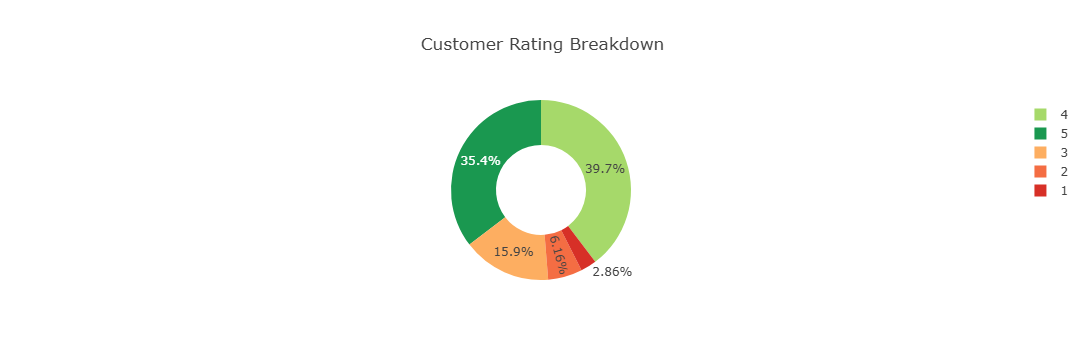

In [90]:
rating_colors = {
    1: '#D73027', 
    2: '#F46D43',  
    3: '#FDAE61',  
    4: '#A6D96A', 
    5: '#1A9850'   
}

rating_counts = (
    df.dropna(subset=['Customer_Rating'])['Customer_Rating']
    .value_counts()
    .sort_index()
    .reset_index()
)

px.pie(
    rating_counts,
    names='Customer_Rating',
    values='count',
    title='Customer Rating Breakdown',
    hole=0.5,
    color='Customer_Rating',
    color_discrete_map=rating_colors
).show()

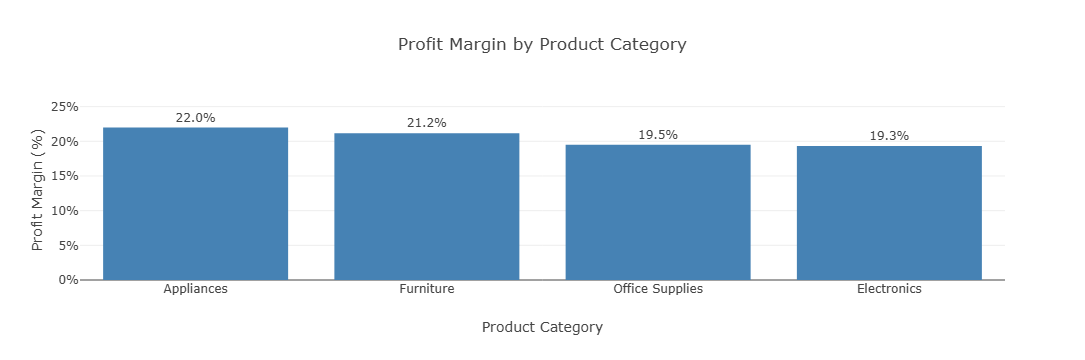

In [91]:
profit_margin = (
    df.groupby('Product_Category', as_index=False)
    .agg(
        Total_Sales=('Sales_Amount', 'sum'),
        Total_Profit=('Profit', 'sum')
    )
)

profit_margin['Profit_Margin'] = (
    profit_margin['Total_Profit'] / profit_margin['Total_Sales'] * 100
)

profit_margin = profit_margin.sort_values(
    'Profit_Margin', ascending=False
)

px.bar(
    profit_margin,
    x='Product_Category',
    y='Profit_Margin',
    title='Profit Margin by Product Category',
    color_discrete_sequence=['#4682B4'],
    text=profit_margin['Profit_Margin'].map(lambda x: f'{x:.1f}%')
).update_layout(
    xaxis_title='Product Category',
    yaxis_title='Profit Margin (%)',
    yaxis_ticksuffix='%',
    showlegend=False
).update_traces(
    textposition='outside',
    cliponaxis=False
).show()

In [96]:
%%writefile streamlit_basics.py
import pandas as pd
import plotly.express as px
import streamlit as st
 
st.set_page_config(page_title="Retail Sales Analysis", layout="wide")
 
st.markdown(
    """
    <h1 style='text-align: center; color: #4682B4;'>
        Retail Sales Analysis
    </h1>
    <p style='text-align: center; font-size: 16px;'>
        An overview of sales, profit and customer trends from 2022–2025
    </p>
    """,
    unsafe_allow_html=True
)
col_left, col_center, col_right = st.columns([1, 6, 1])
with col_center:
    st.image("Retail Img.jpg", use_container_width=True)
 
# cleaned dataset
df = pd.read_csv("cleaned_retail_dataset.csv")
 
# Prepare dates for the monthly sales chart
df["Order_Date"] = pd.to_datetime(df["Order_Date"], errors="coerce")
 
page = st.sidebar.radio(
    "Pages",
    ["Page 1: Sales Overview", "Page 2: Product and Customer Analysis"],
    key="page_navigation",
)
 
st.sidebar.divider()
st.sidebar.subheader("Filters")
st.sidebar.caption("Choose one or more values")
 
year_options = sorted(df["Order_Year"].dropna().astype(int).unique().tolist())
region_options = sorted(df["Region"].dropna().astype(str).unique().tolist())
category_options = sorted(df["Product_Category"].dropna().astype(str).unique().tolist())
channel_options = sorted(df["Sales_Channel"].dropna().astype(str).unique().tolist())
payment_options = sorted(df["Payment_Method"].dropna().astype(str).unique().tolist())
 
selected_years = st.sidebar.multiselect(
    "Order Year", options=year_options, default=[], key="filter_year"
)
selected_regions = st.sidebar.multiselect(
    "Region", options=region_options, default=[], key="filter_region"
)
selected_categories = st.sidebar.multiselect(
    "Product Category", options=category_options, default=[], key="filter_category"
)
selected_channels = st.sidebar.multiselect(
    "Sales Channel", options=channel_options, default=[], key="filter_channel"
)
selected_payment_methods = st.sidebar.multiselect(
    "Payment Method", options=payment_options, default=[], key="filter_payment_method"
)
# Apply selected filters to the dataset
filtered_df = df.copy()
 
if selected_years:
    filtered_df = filtered_df[
        filtered_df["Order_Year"].isin(selected_years)
    ]
 
if selected_regions:
    filtered_df = filtered_df[
        filtered_df["Region"].astype(str).isin(selected_regions)
    ]
 
if selected_categories:
    filtered_df = filtered_df[
        filtered_df["Product_Category"].astype(str).isin(selected_categories)
    ]
 
if selected_channels:
    filtered_df = filtered_df[
        filtered_df["Sales_Channel"].astype(str).isin(selected_channels)
    ]
 
if selected_payment_methods:
    filtered_df = filtered_df[
        filtered_df["Payment_Method"].astype(str).isin(selected_payment_methods)
    ]
 
st.sidebar.caption(
    f"Rows matching filters: {len(filtered_df):,} of {len(df):,}"
)
full_df = df          # keep the original if you ever need it
df = filtered_df      # everything below now uses filtered data
 
# Colours used
category_colors = {
    "Appliances": "#90EE90",
    "Electronics": "#4682B4",
    "Furniture": "#FFA500",
    "Office Supplies": "#FF69B4"
}
 
status_colors = {
    "Completed": "#2E8B57",
    "Shipped": "#4682B4",
    "Returned": "#FFA500",
    "Processing": "#9370DB",
    "Cancelled": "#DC143C"
}
 
return_colors = {
    "Late Delivery": "#990000",
    "Wrong Item": "#D92D2D",
    "Damaged": "#F25353",
    "Other": "#FF8080",
    "Defective": "#FFAAAA",
    "Changed Mind": "#FFCACA"
}
 
shipping_colors = {
    "Standard": "#2E8B57",
    "Next Day": "#4682B4",
    "Express": "#FFA500",
    "Pickup": "#9370DB"
}
 
rating_colors = {
    1: "#D73027",
    2: "#F46D43",
    3: "#FDAE61",
    4: "#A6D96A",
    5: "#1A9850"
}
 
 
# -------------------------
# PAGE 1: SALES OVERVIEW
# -------------------------
if page == "Page 1: Sales Overview":
    st.header("Sales Overview")
 
    total_sales = df["Sales_Amount"].sum()
    total_profit = df["Profit"].sum()
    total_orders = df["Order_ID"].nunique()
    average_order_value = total_sales / total_orders if total_orders else 0
 
    col1, col2, col3, col4 = st.columns(4)
    col1.metric("Total Sales", f"${total_sales:,.0f}")
    col2.metric("Total Profit", f"${total_profit:,.0f}")
    col3.metric("Unique Orders", f"{total_orders:,}")
    col4.metric("Average Order Value", f"${average_order_value:,.2f}")
    st.dataframe(df)
 
    # Orders by Year
    st.subheader("Orders by Year")
    orders_by_year = df["Order_Year"].value_counts().reset_index()
    fig_year = px.bar(
        orders_by_year,
        x="Order_Year",
        y="count",
        title="Orders by Year",
        color_discrete_sequence=["lightblue"]
    )
    fig_year.update_xaxes(dtick=1, tickmode="linear")
    st.plotly_chart(fig_year, use_container_width=True)
 
    # Monthly Sales Trend
    st.subheader("Monthly Sales Trend")
 
    # Create a copy so the original dataset remains unchanged
    monthly_df = df.copy()
 
    # Convert Order_Date to datetime format
    monthly_df["Order_Date"] = pd.to_datetime(
        monthly_df["Order_Date"],
        errors="coerce"
    )
 
    # Remove rows with invalid dates for this chart
    monthly_df = monthly_df.dropna(subset=["Order_Date"])
 
    # Group sales by month
    monthly_df["Month"] = monthly_df["Order_Date"].dt.to_period("M")
 
    monthly_sales = (
        monthly_df.groupby("Month", as_index=False)["Sales_Amount"]
        .sum()
    )
 
    # Convert monthly periods back to dates
    monthly_sales["Order_Date"] = (
        monthly_sales["Month"].dt.to_timestamp()
    )
 
    # Chart
    fig_monthly = px.line(
        monthly_sales,
        x="Order_Date",
        y="Sales_Amount",
        title="Monthly Sales Trend",
        markers=True
    ).update_traces(
        line_color="green"
    ).update_xaxes(
        range=["2022-01-01", "2025-12-31"]
    )
 
    # Display
    st.plotly_chart(fig_monthly, width="stretch")
 
    col1, col2 = st.columns(2)
 
    with col1:
        st.subheader("Sales by Product Category")
        category_sales = df.groupby(
            "Product_Category", as_index=False
        )["Sales_Amount"].sum()
 
        fig_category_sales = px.bar(
            category_sales,
            x="Sales_Amount",
            y="Product_Category",
            orientation="h",
            title="Total Sales by Product Category",
            color="Product_Category",
            color_discrete_map=category_colors
        ).update_layout(
            yaxis={"categoryorder": "total ascending"}
        )
        st.plotly_chart(fig_category_sales, use_container_width=True)
 
    with col2:
        st.subheader("Profit by Product Category")
        category_profit = df.groupby(
            "Product_Category", as_index=False
        )["Profit"].sum()
 
        fig_category_profit = px.bar(
            category_profit,
            x="Profit",
            y="Product_Category",
            orientation="h",
            title="Total Profit by Product Category",
            color="Product_Category",
            color_discrete_map=category_colors,
            text_auto=".2s"
        ).update_layout(
            yaxis={"categoryorder": "total ascending"},
            xaxis_title="Total Profit",
            yaxis_title="Product Category"
        )
        st.plotly_chart(fig_category_profit, use_container_width=True)
 
    col1, col2 = st.columns(2)
 
    with col1:
        st.subheader("Sales by Sales Channel")
        sales_channel = (
            df.groupby("Sales_Channel", as_index=False)["Sales_Amount"]
            .sum()
            .sort_values("Sales_Amount", ascending=False)
        )
 
        channel_colors = {
            "Online": "#4682B4",
            "B2B Portal": "#90EE90",
            "Phone Order": "#ADFF2F",
            "Retail Store": "#FF8C00"
        }
 
        fig_channel = px.bar(
            sales_channel,
            x="Sales_Channel",
            y="Sales_Amount",
            title="Total Sales by Sales Channel",
            color="Sales_Channel",
            color_discrete_map=channel_colors,
            text=sales_channel["Sales_Amount"].map(lambda x: f"{x:,.0f}"),
            category_orders={"Sales_Channel": sales_channel["Sales_Channel"].tolist()}
        ).update_layout(
            xaxis_title="Sales Channel",
            yaxis_title="Total Sales",
            yaxis_tickprefix="$",
            yaxis_tickformat=",.0f",
            showlegend=False
        ).update_traces(
            textposition="outside"
        )
        st.plotly_chart(fig_channel, use_container_width=True)
 
    with col2:
        st.subheader("Sales by Region")
        sales_region = (
            df.groupby("Region", as_index=False)["Sales_Amount"]
            .sum()
            .sort_values("Sales_Amount", ascending=True)
        )
 
        fig_region = px.bar(
            sales_region,
            x="Sales_Amount",
            y="Region",
            orientation="h",
            title="Total Sales by Region",
            color_discrete_sequence=["#4682B4"],
            text=sales_region["Sales_Amount"].map(lambda x: f"{x:,.0f}")
        ).update_layout(
            xaxis_title="Total Sales",
            yaxis_title="Region",
            xaxis_tickprefix="$",
            xaxis_tickformat=",.0f",
            showlegend=False
        ).update_traces(
            textposition="outside",
            cliponaxis=False
        )
        st.plotly_chart(fig_region, use_container_width=True)
 
    # Order Status Distribution
    st.subheader("Order Status Distribution")
    status_counts = df["Order_Status"].value_counts().reset_index()
    fig_status = px.bar(
        status_counts,
        x="Order_Status",
        y="count",
        title="Order Status Distribution",
        color="Order_Status",
        color_discrete_map=status_colors,
        text_auto=True
    ).update_layout(
        xaxis_title="Order Status",
        yaxis_title="Number of Orders"
    )
    st.plotly_chart(fig_status, use_container_width=True)
 
# -------------------------
# PAGE 2: PRODUCT AND CUSTOMER ANALYSIS
# -------------------------
elif page == "Page 2: Product and Customer Analysis":
    st.header("Product and Customer Analysis")
 
    col1, col2 = st.columns(2)
 
    with col1:
        st.subheader("Return Reasons Distribution")
        return_counts = (
            df[df["Return_Flag"] == "Yes"]["Return_Reason"]
            .value_counts()
            .reindex(
                ["Late Delivery", "Wrong Item", "Damaged", "Other", "Defective", "Changed Mind"],
                fill_value=0
            )
            .rename_axis("Return_Reason")
            .reset_index(name="count")
            .sort_values("count", ascending=False)
        )
 
        fig_returns = px.bar(
            return_counts,
            x="Return_Reason",
            y="count",
            title="Return Reasons Distribution",
            color="Return_Reason",
            color_discrete_map=return_colors,
            text_auto=True,
            category_orders={"Return_Reason": return_counts["Return_Reason"].tolist()}
        ).update_layout(
            xaxis_title="Return Reason",
            yaxis_title="Number of Returns"
        )
        st.plotly_chart(fig_returns, use_container_width=True)
 
    with col2:
        st.subheader("Return Rate by Product Category")
        return_rate = (
            df.groupby("Product_Category")
            .agg(
                Total_Orders=("Order_ID", "nunique"),
                Returned_Orders=("Return_Flag", lambda x: (x == "Yes").sum())
            )
            .reset_index()
        )
        return_rate["Return_Rate"] = (
            return_rate["Returned_Orders"] / return_rate["Total_Orders"] * 100
        )
        return_rate = return_rate.sort_values("Return_Rate", ascending=False)
 
        fig_return_rate = px.bar(
            return_rate,
            x="Product_Category",
            y="Return_Rate",
            title="Return Rate by Product Category",
            color="Product_Category",
            color_discrete_map=category_colors,
            text=return_rate["Return_Rate"].map(lambda x: f"{x:.1f}%"),
            category_orders={"Product_Category": return_rate["Product_Category"].tolist()}
        ).update_layout(
            xaxis_title="Product Category",
            yaxis_title="Return Rate (%)",
            yaxis_ticksuffix="%",
            showlegend=False
        ).update_traces(
            textposition="outside"
        )
        st.plotly_chart(fig_return_rate, use_container_width=True)
 
    col1, col2 = st.columns(2)
 
    with col1:
        st.subheader("Delivery Time by Shipping Method")
        delivery_df = df.dropna(subset=["Delivery_Days"])
        delivery_order = (
            delivery_df.groupby("Shipping_Method")["Delivery_Days"]
            .mean()
            .sort_values(ascending=False)
            .index.tolist()
        )
 
        fig_delivery = px.box(
            delivery_df,
            x="Shipping_Method",
            y="Delivery_Days",
            color="Shipping_Method",
            color_discrete_map=shipping_colors,
            title="Delivery Time by Shipping Method",
            category_orders={"Shipping_Method": delivery_order}
        ).update_layout(
            xaxis_title="Shipping Method",
            yaxis_title="Delivery Days"
        )
        st.plotly_chart(fig_delivery, use_container_width=True)
 
    with col2:
        st.subheader("Customer Rating Breakdown")
        rating_counts = (
            df.dropna(subset=["Customer_Rating"])["Customer_Rating"]
            .value_counts()
            .sort_index()
            .reset_index()
        )
 
        fig_ratings = px.pie(
            rating_counts,
            names="Customer_Rating",
            values="count",
            title="Customer Rating Breakdown",
            hole=0.5,
            color="Customer_Rating",
            color_discrete_map=rating_colors
        )
        st.plotly_chart(fig_ratings, use_container_width=True)
 
    st.subheader("Profit Margin by Product Category")
    profit_margin = (
        df.groupby("Product_Category", as_index=False)
        .agg(
            Total_Sales=("Sales_Amount", "sum"),
            Total_Profit=("Profit", "sum")
        )
    )
    profit_margin["Profit_Margin"] = (
        profit_margin["Total_Profit"] / profit_margin["Total_Sales"] * 100
    )
    profit_margin = profit_margin.sort_values("Profit_Margin", ascending=False)
 
    fig_margin = px.bar(
        profit_margin,
        x="Product_Category",
        y="Profit_Margin",
        title="Profit Margin by Product Category",
        color_discrete_sequence=["#4682B4"],
        text=profit_margin["Profit_Margin"].map(lambda x: f"{x:.1f}%")
    ).update_layout(
        xaxis_title="Product Category",
        yaxis_title="Profit Margin (%)",
        yaxis_ticksuffix="%",
        showlegend=False
    ).update_traces(
        textposition="outside",
        cliponaxis=False
    )
    st.plotly_chart(fig_margin, use_container_width=True)

Overwriting streamlit_basics.py


In [97]:
! streamlit run streamlit_basic

Usage: streamlit run [OPTIONS] [TARGET] [ARGS]...
Try 'streamlit run --help' for help.

Error: Streamlit requires raw Python (.py) files, but the provided file has no extension.
For more information, please see https://docs.streamlit.io
